In [63]:
from dotenv import load_dotenv
load_dotenv()

True

In [74]:
from langgraph.graph import StateGraph, START, END
from langgraph.types import interrupt, Command
from langgraph.checkpoint.memory import InMemorySaver
from langchain_anthropic import ChatAnthropic
from pydantic import BaseModel

In [ ]:
# STEPS
# State -> Nodes -> Graph 

In [66]:
# State to store data
class MailState(BaseModel):
    query: str = ""
    draft:str = ""
    human_feedback: str = ""
    final_response: str = ""

In [67]:
llm = ChatAnthropic(model="claude-sonnet-5-5")
memory = InMemorySaver()

In [68]:
# Nodes

# this node is responsible for:
# - based on the user question
# - store the informations in the draft
def DraftEmail(state:MailState) -> MailState:
    draft = llm.invoke(state.query).content
    state.draft = draft
    return state

# this node will determine, either we have to continue, or return to the draft for update the info.
# for human intract, we use "interrucpt" method
def HumanFeedback(state:MailState) -> MailState:
    feedback = interrupt({
        "draft_email": state.draft, # tell the model about the current draft/email
        "question": "Do you want to continue or modify the email?"
    })

    fb = (feedback or "").strip().lower()
    if fb in ["approved", "ok", "yes"]:
        state.human_feedback = ""
        return state
    else:
        state.human_feedback = feedback
        return state

def FinalResponse(state:MailState) -> MailState:
    if state.human_feedback:
        # if human gave some feed back, add it to the final response.
        state.final_response = state.human_feedback
        return state
    else:
        # if human approved, we can return the draft as final response.
        print("Email has been sent.")
        state.final_response = "Email has been sent."
        return state
    

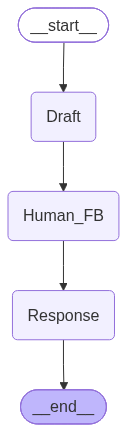

In [69]:
graph_builder = StateGraph(MailState)

# nodes
graph_builder.add_node("Draft", DraftEmail)
graph_builder.add_node("Human_FB", HumanFeedback)
graph_builder.add_node("Response", FinalResponse)

# edges
graph_builder.add_edge(START, "Draft")
graph_builder.add_edge("Draft", "Human_FB")
graph_builder.add_edge("Human_FB", "Response")
graph_builder.add_edge("Response", END)

# compile graph
graph = graph_builder.compile(checkpointer=memory)
graph

In [70]:
config = {"configurable":{"thread_id":"1"}}
res = graph.invoke(
    {"query": "Write an email to my boss asking for a raise."},
    config=config
)


In [73]:
res

{'query': 'Write an email to my boss asking for a raise.',
 'draft': 'Subject: Request for Salary Review\n\nDear [Boss’s Name],\n\nI hope you’re doing well. I am writing to discuss the possibility of a salary adjustment that reflects my contributions and the increased responsibilities I have taken on over the past year.\n\nSince joining the team, I have:\n\n- Successfully led the [Project Name] to completion two weeks ahead of schedule, resulting in a cost saving of $[X].\n- Increased our department’s efficiency by implementing [specific process/tool], which has reduced turnaround time by [Y]%.\n- Consistently exceeded my performance targets, achieving an average rating of [Z]% above goal in the last two quarterly reviews.\n- Mentored three junior team members, helping them achieve their own performance milestones.\n\nThese accomplishments, along with my ongoing commitment to delivering high‑quality work and supporting our team’s objectives, have expanded the scope of my role beyond th

In [1]:
# we use "command" method to give feedback to AI
# res2 = graph.invoke(Command(resume="I do not want to send this email."), config=config)
res2 = graph.invoke(Command(resume="yes"), config=config)

NameError: name 'graph' is not defined

In [77]:
res2

{'query': 'Write an email to my boss asking for a raise.',
 'draft': 'Subject: Request for Salary Review\n\nDear [Boss’s Name],\n\nI hope you’re doing well. I am writing to discuss the possibility of a salary adjustment that reflects my contributions and the increased responsibilities I have taken on over the past year.\n\nSince joining the team, I have:\n\n- Successfully led the [Project Name] to completion two weeks ahead of schedule, resulting in a cost saving of $[X].\n- Increased our department’s efficiency by implementing [specific process/tool], which has reduced turnaround time by [Y]%.\n- Consistently exceeded my performance targets, achieving an average rating of [Z]% above goal in the last two quarterly reviews.\n- Mentored three junior team members, helping them achieve their own performance milestones.\n\nThese accomplishments, along with my ongoing commitment to delivering high‑quality work and supporting our team’s objectives, have expanded the scope of my role beyond th

In [ ]:
graph.invoke(Command(resume="yes"), config=config)